# Problem set 6: Optimization

We continue with the consumer problem from Lecture 6. The aim is to formulate the problem carefully, solve it on a grid, and then use numerical optimizers from `scipy.optimize`.

**Table of contents**<a id='toc0_'></a>    
- 1. [CES function](#toc1_)    
- 2. [Value-of-choice](#toc2_)    
- 3. [Grid search](#toc3_)    
- 4. [`scipy.optimize`](#toc4_)    
- 5. [Two choices with SLSQP](#toc5_)    
- 6. [Optional: Price shock](#toc6_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=2
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [1]:
import numpy as np
from scipy import optimize

## 1. <a id='toc1_'></a>[CES function](#toc0_)

Implement a Python version of this function. With $\beta>0$ the formula takes a negative power of zero when a quantity is zero, which fails. Use an `if` and return `0.0` when either quantity is zero; that is the limit value of CES utility there. Your function then takes one bundle at a time.

$$ 
u(x_1,x_2) = (\alpha x_1^{-\beta} + (1-\alpha) x_2^{-\beta})^{-1/\beta} 
$$

In [2]:
# write your own code here

In [3]:
import A1

## 2. <a id='toc2_'></a>[Value-of-choice](#toc0_)

The consumer faces the following budget constraint:

$$ p_1 x_1 + p_2 x_2 \le I, \quad x_1 \ge 0,\; x_2 \ge 0. $$

**Tasks:** Use your function from above that contains the CES utility function and embed it into another function *value_of_choice_ces* that returns the value of utility *u*. Use only $x_1$ as input into the function and compute $x_2$ within the function,

$$x_2 = (I - p_1x_1)/p_2.$$

Evaluate for some $x_1$ values.

In [4]:
# use these baseline parameters
alpha = 0.5
beta = 0.5
I = 10
p1 = 1
p2 = 2
x1_vec = [0.5,1.0,1.5]

In [5]:
# write your own code here

In [6]:
import A2

Next, we will compare different methods to solve the consumer problem.

## 3. <a id='toc3_'></a>[Grid search](#toc0_)

Set up a grid of the budget set and solve the consumer problem on the grid.

**Idea:** Search over a grid for  $x_1 \in [0, I/p_1]$, and  $x_2 \in [0, I/p_2]$ to find the values of $x_1$ and $x_2$ that maximize utility.


**Task A:** Adapt the 2D grid search from Lecture 6, Section 2 to CES utility. Use `N1 = N2 = 100`, so you try 10,000 pairs, and count the pairs tried. Report the best bundle, its utility and the budget left.

In [7]:
N1 = 100
N2 = 100

# write your own code here

In [8]:
import A3_A
_ = A3_A.grid_search_2d(A1.utility_ces, alpha, beta, I, p1, p2, N1, N2)

Pairs tried: 10000
Best grid bundle: (4.44444, 2.77778)
Utility: 3.46557
Budget left: 0.00000


**Search the budget line.** CES utility is strictly increasing in both goods, so the optimum spends the whole budget. This turns the 2D search into a **1D search**: choose a grid for $x_1 \in [0, I/p_1]$ and set $x_2 = (I-p_1 x_1)/p_2$.

**Task B:** Adapt the budget-line grid from Lecture 6, Section 3 to CES utility. Use `N = 10000` points, the same number of tries as the $100\times100$ grid. Because your CES function uses `if`, it takes one bundle at a time: loop over the grid points to fill a utility array, then use `np.argmax`. Which search is more accurate for the same effort?

In [9]:
# write your own code here

In [10]:
import A3_B
_ = A3_B.grid_search_line(A1.utility_ces, alpha, beta, I, p1, p2, N=10000)

Utility evaluations: 10000
Best budget-line bundle: (4.42444, 2.78778)
Utility: 3.46561
Budget left: 0.00000


## 4. <a id='toc4_'></a>[`scipy.optimize`](#toc0_)

**Task:** Solve the consumer problem using `scipy.optimize.minimize_scalar`, as in Lecture 6, Section 4.

1. Define an objective function that returns minus utility along the budget line.
2. Pass the parameters with `args` and use `method='bounded'` with bounds $0 \leq x_1 \leq I/p_1$.
3. Check `.success`, then print the optimal bundle and compare it with the grid-search solutions.
4. How many function evaluations (`.nfev`) did the solver need, compared with the 10,000 tries of each grid?

In [11]:
### write your code here ###

In [12]:
import A4
_ = A4.solve_with_minimize_scalar(A1.utility_ces, alpha, beta, I, p1, p2)

Bundle: (4.42493, 2.78753)
Utility: 3.46561
Budget left: 0.00000
Function evaluations: 10


## 5. <a id='toc5_'></a>[Two choices with SLSQP](#toc0_)

**Task:** Now let the solver choose **both** quantities with `optimize.minimize` and `method='SLSQP'`, as in Lecture 6, Section 5. Give it bounds for each quantity and the budget as an inequality dictionary.

1. Compare the bundle and the number of function evaluations with `minimize_scalar`.
2. Solve again from three different affordable starting bundles. Do all starts end at the same bundle?

In [13]:
### write your code here ###

In [14]:
import A5
_ = A5.solve_with_slsqp(A1.utility_ces, alpha, beta, I, p1, p2)

start [1. 1.] -> bundle (4.42492, 2.78754); budget left: -0.00000; evaluations: 21; success: True
start [4. 2.] -> bundle (4.42444, 2.78778); budget left: 0.00000; evaluations: 15; success: True
start [9.  0.2] -> bundle (4.42502, 2.78749); budget left: 0.00000; evaluations: 18; success: True


## 6. <a id='toc6_'></a>[Optional: Price shock](#toc0_)

**Goal.** Study how the optimal bundle and the consumer's welfare react when the price of good 1 doubles, $p_1 \rightarrow 2p_1$, and how the response depends on the CES curvature parameter $\beta$.

The elasticity of substitution is $1/(1+\beta)$:
- a smaller $\beta$ means that the goods are easier to substitute;
- a larger $\beta$ means that the goods are more complementary.

See **Problem Set 5** for an illustration of the indifference curves.

**Task:**
- For each $\beta \in \{0.1, 0.3, 0.5, 0.7, 0.9\}$, compute the optimum $(x_1^\star, x_2^\star, u^\star)$ at the baseline prices and after $p_1$ doubles.
- For each $\beta$, report the percentage change relative to the baseline.
- Plot two panels: Panel A with the quantity responses, and Panel B with the welfare response.

In [15]:
## write your code

  beta      %dx1      %dx2       %du
------------------------------------
  0.10    -48.37     -3.05    -28.90
  0.30    -45.66     -7.39    -28.30
  0.50    -43.50    -10.31    -27.86
  0.70    -41.74    -12.41    -27.52
  0.90    -40.28    -13.99    -27.26


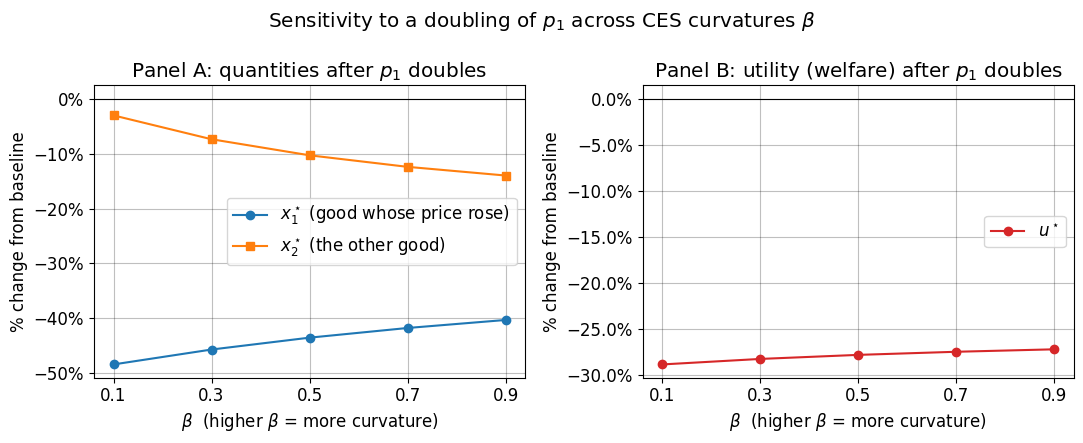

In [16]:
import A6
A6.price_shock_sensitivity(A1.utility_ces, alpha, I, p1, p2)

**Interpretation:**

- **Good 1.** $x_1^\star$ falls after its price rises. The fall is larger when $\beta$ is small because the consumer can substitute more easily toward good 2.

- **Good 2.** $x_2^\star$ also falls for these parameter values. A substitution effect pushes demand toward good 2, while the fall in real income pushes demand down. Here, the income effect is stronger. The decline is smaller when substitution is easier.

- **Welfare.** $u^\star$ falls for every value of $\beta$. In this example, the quantity responses vary more across $\beta$ than the welfare response.